## 1. Imports


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load CSV (relative to notebooks/)
df = pd.read_csv("../data/raw/Microsoft_Stock.csv")

# Convert dates and sort oldest to newest
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y %H:%M:%S")
df = df.sort_values("Date").reset_index(drop=True)

print(df.shape)
print(df.dtypes)
print(df.head())

(1511, 6)
Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object
                 Date   Open   High    Low  Close    Volume
0 2015-04-01 16:00:00  40.60  40.76  40.31  40.72  36865322
1 2015-04-02 16:00:00  40.66  40.74  40.12  40.29  37487476
2 2015-04-06 16:00:00  40.34  41.78  40.18  41.55  39223692
3 2015-04-07 16:00:00  41.61  41.91  41.31  41.53  28809375
4 2015-04-08 16:00:00  41.48  41.69  41.04  41.42  24753438


## 2. Checking time range

In [24]:
print("Start:", df["Date"].min())
print("End:", df["Date"].max())
print("Number of records:", len(df))

print("\nMost common gaps between dates:")
print(df["Date"].diff().value_counts().head())

Start: 2015-04-01 16:00:00
End: 2021-03-31 16:00:00
Number of records: 1511

Most common gaps between dates:
Date
1 days 00:00:00    1179
3 days 00:00:00     267
4 days 00:00:00      40
2 days 00:00:00       6
1 days 21:00:00       4
Name: count, dtype: int64


## 3. Checking for data quality issues

In [25]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicate dates:")
print(df["Date"].duplicated().sum())

print("\nMissing values by row:")
print(df[df.isna().any(axis=1)].head())

# Check any duplicate dates before proceeding
print("\nDuplicate-date rows:")
print(df[df["Date"].duplicated(keep=False)].head(10))

Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate dates:
0

Missing values by row:
Empty DataFrame
Columns: [Date, Open, High, Low, Close, Volume]
Index: []

Duplicate-date rows:
Empty DataFrame
Columns: [Date, Open, High, Low, Close, Volume]
Index: []


## 4. Statistical Visualizations

         count          mean           std        min           25%  \
Open    1511.0  1.073860e+02  5.669133e+01      40.34  5.786000e+01   
High    1511.0  1.084375e+02  5.738228e+01      40.74  5.806000e+01   
Low     1511.0  1.062945e+02  5.597716e+01      39.72  5.742000e+01   
Close   1511.0  1.074221e+02  5.670230e+01      40.29  5.785500e+01   
Volume  1511.0  3.019863e+07  1.425266e+07  101612.00  2.136213e+07   

                50%           75%           max  
Open          93.99  1.394400e+02  2.450300e+02  
High          95.10  1.403250e+02  2.461300e+02  
Low           92.92  1.378250e+02  2.429200e+02  
Close         93.86  1.389650e+02  2.449900e+02  
Volume  26629615.00  3.431962e+07  1.352271e+08  


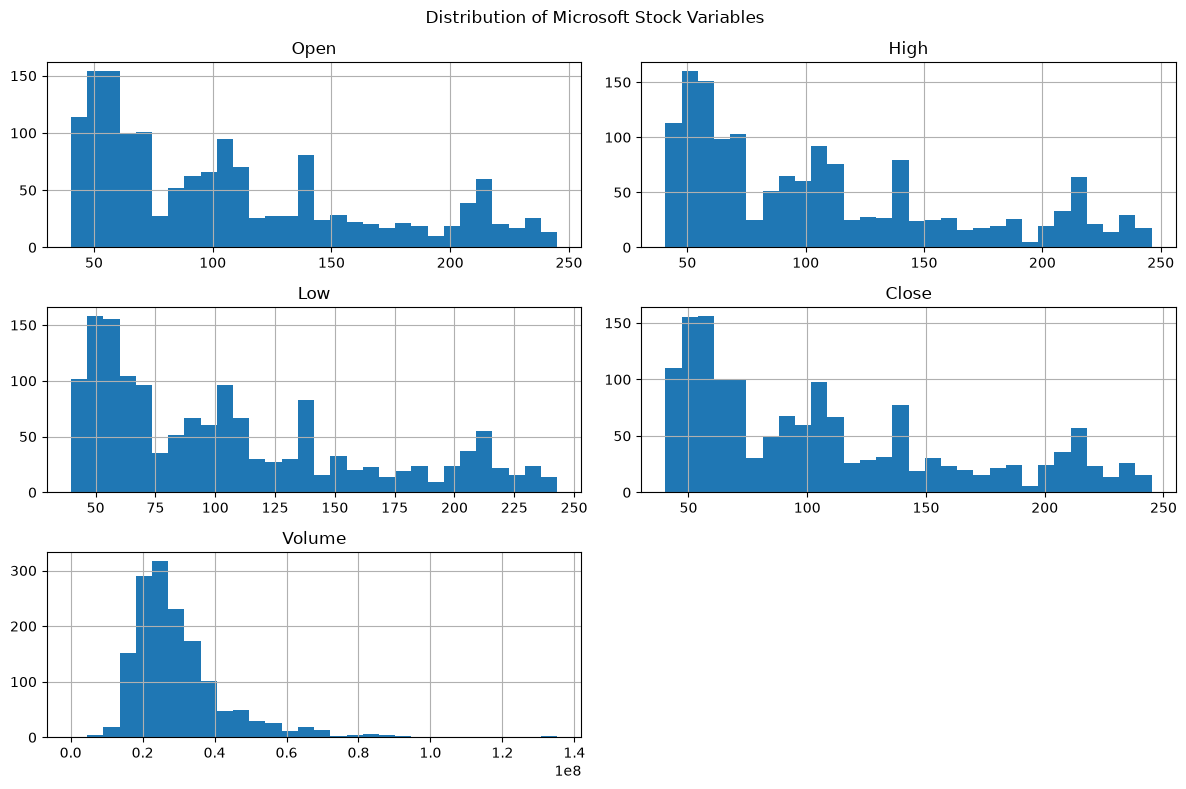

In [26]:
numeric_cols = ["Open", "High", "Low", "Close", "Volume"]

print(df[numeric_cols].describe().T)

df[numeric_cols].hist(figsize=(12, 8), bins=30)
plt.suptitle("Distribution of Microsoft Stock Variables")
plt.tight_layout()
plt.show()

## 5. Feature Engineering

In [27]:
# Calendar features and daily return
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["Daily_Return"] = df["Close"].pct_change(fill_method=None) * 100

# Lagged closing prices
for lag in [1, 5, 10]:
    df[f"Close_Lag_{lag}"] = df["Close"].shift(lag)

# Moving averages
for window in [7, 20, 50]:
    df[f"MA_{window}"] = df["Close"].rolling(window).mean()

# Closing price of the next trading day
df["Target_Next_Close"] = df["Close"].shift(-1)

print(df[["Date", "Close", "Close_Lag_1", "MA_7", "Target_Next_Close"]].tail(10))

                    Date   Close  Close_Lag_1        MA_7  Target_Next_Close
1501 2021-03-18 16:00:00  230.72       237.04  235.082857             230.35
1502 2021-03-19 16:00:00  230.35       230.72  234.787143             235.99
1503 2021-03-22 16:00:00  235.99       230.35  234.624286             237.58
1504 2021-03-23 16:00:00  237.58       235.99  234.885714             235.46
1505 2021-03-24 16:00:00  235.46       237.58  234.978571             232.34
1506 2021-03-25 16:00:00  232.34       235.46  234.211429             236.48
1507 2021-03-26 16:00:00  236.48       232.34  234.131429             235.24
1508 2021-03-29 16:00:00  235.24       236.48  234.777143             231.85
1509 2021-03-30 16:00:00  231.85       235.24  234.991429             235.77
1510 2021-03-31 16:00:00  235.77       231.85  234.960000                NaN


/tmp/ipykernel_183813/1703102066.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["DayOfWeek"] = df["Date"].dt.dayofweek


## 6. Five Analytical Questions


#### 6.1. How did Microsoft's closing stock price change from 2015 to 2021?

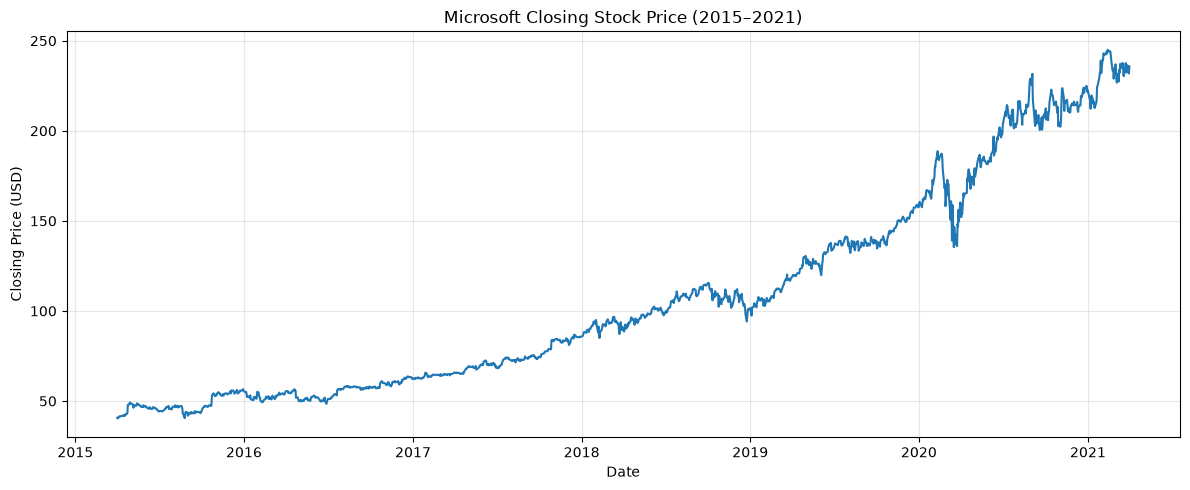

First close: 40.72
Last close: 235.77
Overall change (%): 479.0


In [28]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.title("Microsoft Closing Stock Price (2015–2021)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("First close:", df["Close"].iloc[0])
print("Last close:", df["Close"].iloc[-1])
print("Overall change (%):", round((df["Close"].iloc[-1] / df["Close"].iloc[0] - 1) * 100, 2))

#### 6.2. How is trading volumne related to daily stock returns?

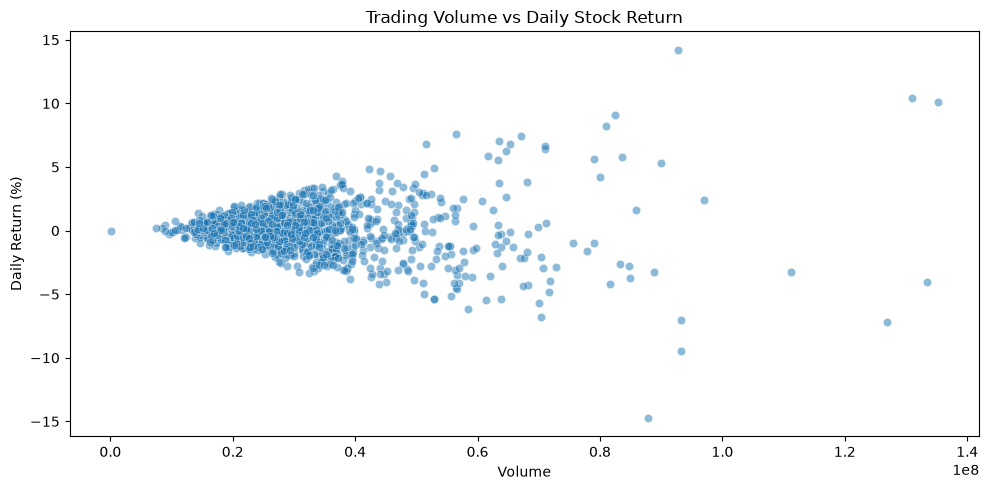

                Volume  Daily_Return
Volume        1.000000     -0.035538
Daily_Return -0.035538      1.000000


In [29]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="Volume", y="Daily_Return", alpha=0.5)
plt.title("Trading Volume vs Daily Stock Return")
plt.xlabel("Volume")
plt.ylabel("Daily Return (%)")
plt.tight_layout()
plt.show()

print(df[["Volume", "Daily_Return"]].corr())

#### 6.3 How strongly do closing prices correlate with lagged prices?

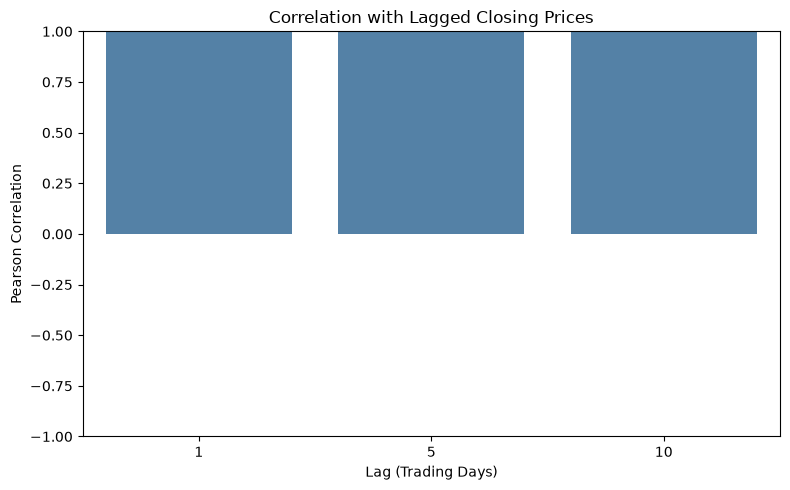

   Lag  Correlation
0    1     0.999136
1    5     0.997149
2   10     0.994872


In [30]:
lags = [1, 5, 10]
correlations = [df["Close"].corr(df[f"Close_Lag_{lag}"]) for lag in lags]

plt.figure(figsize=(8, 5))
sns.barplot(x=[str(lag) for lag in lags], y=correlations, color="steelblue")
plt.title("Correlation with Lagged Closing Prices")
plt.xlabel("Lag (Trading Days)")
plt.ylabel("Pearson Correlation")
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"Lag": lags, "Correlation": correlations}))

#### 6.4. What do 7, 20 and 50-day moving avgs. show?

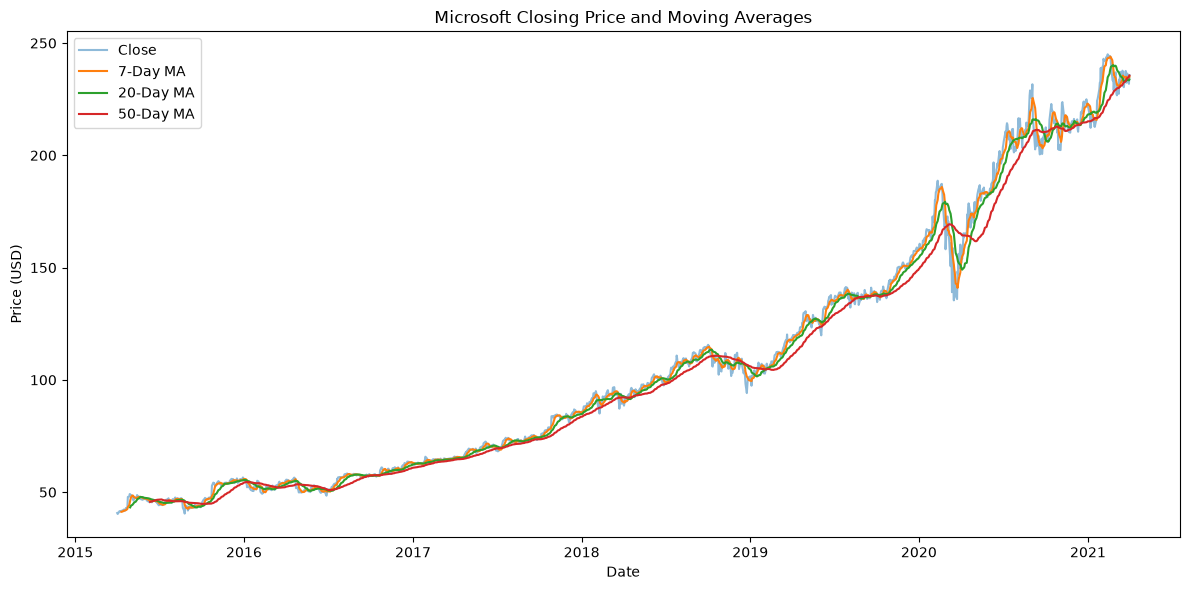

                    Date   Close    MA_7    MA_20     MA_50
1510 2021-03-31 16:00:00  235.77  234.96  233.807  235.5338


In [31]:
plt.figure(figsize=(12, 6))
plt.plot(df["Date"], df["Close"], label="Close", alpha=0.5)
plt.plot(df["Date"], df["MA_7"], label="7-Day MA")
plt.plot(df["Date"], df["MA_20"], label="20-Day MA")
plt.plot(df["Date"], df["MA_50"], label="50-Day MA")
plt.title("Microsoft Closing Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.tight_layout()
plt.show()

print(df[["Date", "Close", "MA_7", "MA_20", "MA_50"]].tail(1))

#### 6.5. How did daily return volatility differ by year?

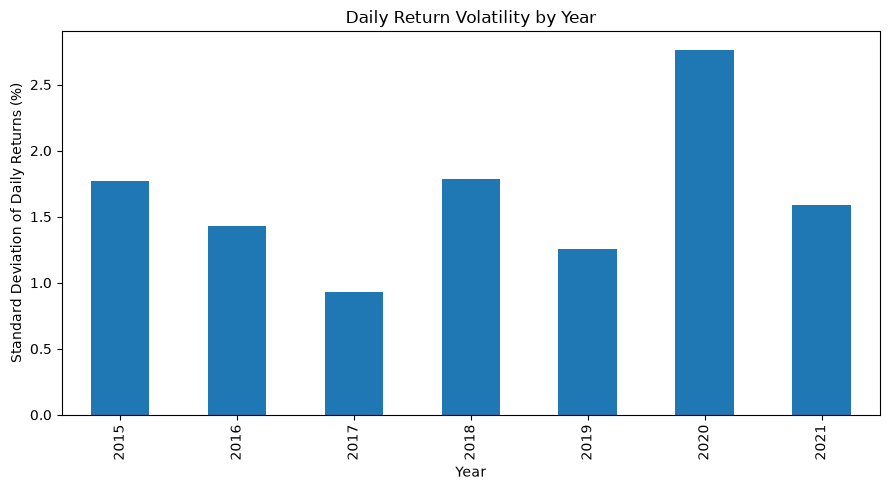

Year
2015    1.773742
2016    1.429376
2017    0.932016
2018    1.782208
2019    1.253214
2020    2.764920
2021    1.589231
Name: Daily_Return, dtype: float64


In [32]:
annual_volatility = df.groupby("Year")["Daily_Return"].std()

plt.figure(figsize=(9, 5))
annual_volatility.plot(kind="bar")
plt.title("Daily Return Volatility by Year")
plt.xlabel("Year")
plt.ylabel("Standard Deviation of Daily Returns (%)")
plt.tight_layout()
plt.show()

print(annual_volatility)

## 7. Prepare the modeling dataset

In [33]:
feature_cols = [
    "Open", "High", "Low", "Close", "Volume",
    "Year", "Month", "DayOfWeek", "Daily_Return",
    "Close_Lag_1", "Close_Lag_5", "Close_Lag_10",
    "MA_7", "MA_20", "MA_50"
]

model_df = df.dropna(subset=feature_cols + ["Target_Next_Close"]).copy()

print("Original rows:", len(df))
print("Model-ready rows:", len(model_df))
print("Removed rows:", len(df) - len(model_df))

Original rows: 1511
Model-ready rows: 1461
Removed rows: 50


## 8. Save processed CSV files and the charts

In [34]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)

df.to_csv("../data/processed/microsoft_features.csv", index=False)
model_df.to_csv("../data/processed/microsoft_model_ready.csv", index=False)

# Save a compact statistics table too
df[numeric_cols].describe().T.to_csv("../data/processed/descriptive_statistics.csv")

print("Saved processed CSV files.")

Saved processed CSV files.


#### Save the figures

In [35]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.title("Microsoft Closing Stock Price (2015–2021)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/figures/q1_price_trend.png", dpi=300)
plt.close()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="Volume", y="Daily_Return", alpha=0.5)
plt.title("Trading Volume vs Daily Stock Return")
plt.xlabel("Volume")
plt.ylabel("Daily Return (%)")
plt.tight_layout()
plt.savefig("../outputs/figures/q2_volume_returns.png", dpi=300)
plt.close()

plt.figure(figsize=(8, 5))
sns.barplot(x=[str(lag) for lag in lags], y=correlations, color="steelblue")
plt.title("Correlation with Lagged Closing Prices")
plt.xlabel("Lag (Trading Days)")
plt.ylabel("Pearson Correlation")
plt.ylim(-1, 1)
plt.tight_layout()
plt.savefig("../outputs/figures/q3_lag_correlations.png", dpi=300)
plt.close()

plt.figure(figsize=(12, 6))
plt.plot(df["Date"], df["Close"], label="Close", alpha=0.5)
plt.plot(df["Date"], df["MA_7"], label="7-Day MA")
plt.plot(df["Date"], df["MA_20"], label="20-Day MA")
plt.plot(df["Date"], df["MA_50"], label="50-Day MA")
plt.title("Microsoft Closing Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/figures/q4_moving_averages.png", dpi=300)
plt.close()

plt.figure(figsize=(9, 5))
annual_volatility.plot(kind="bar")
plt.title("Daily Return Volatility by Year")
plt.xlabel("Year")
plt.ylabel("Standard Deviation of Daily Returns (%)")
plt.tight_layout()
plt.savefig("../outputs/figures/q5_annual_volatility.png", dpi=300)
plt.close()

print("Saved five PNG charts to outputs/figures/.")

Saved five PNG charts to outputs/figures/.
